In [1]:
import sys
!{sys.executable} -m pip install pandas numpy


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: C:\Users\MarsTech\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import random

np.random.seed(42)

# -------------------------
# 参数
# -------------------------
num_players = 500
start_date = datetime(2024, 1, 1)

# -------------------------
# Players 表
# -------------------------
players = []

for i in range(1, num_players + 1):
    signup = start_date + timedelta(days=np.random.randint(0, 30))
    region = random.choice(["NA", "EU", "ASIA"])
    platform = random.choice(["PC", "Console"])
    
    players.append([i, signup.date(), region, platform])

players_df = pd.DataFrame(players, columns=[
    "player_id", "signup_date", "region", "platform"
])

# -------------------------
# Sessions 表
# -------------------------
sessions = []
session_id = 1

for player in players_df.itertuples():
    activity_level = np.random.choice(
        ["high", "medium", "low"], p=[0.3, 0.5, 0.2]
    )
    
    if activity_level == "high":
        num_sessions = np.random.randint(20, 50)
    elif activity_level == "medium":
        num_sessions = np.random.randint(10, 20)
    else:
        num_sessions = np.random.randint(3, 10)
    
    for _ in range(num_sessions):
        login_date = player.signup_date + timedelta(days=np.random.randint(0, 30))
        duration = np.random.exponential(scale=30)
        
        sessions.append([
            session_id,
            player.player_id,
            login_date,
            round(duration, 2)
        ])
        
        session_id += 1

sessions_df = pd.DataFrame(sessions, columns=[
    "session_id", "player_id", "login_date", "session_duration"
])

# -------------------------
# Missions 表
# -------------------------
missions = []
mission_id = 1

mission_types = ["Defense", "Survival", "Exterminate", "Capture", "Interception"]

for session in sessions_df.itertuples():
    num_missions = np.random.randint(1, 5)
    
    for _ in range(num_missions):
        mission_type = random.choice(mission_types)
        duration = np.random.uniform(5, 20)
        success = np.random.choice([1, 0], p=[0.85, 0.15])
        reward = int(duration * np.random.uniform(10, 20))
        
        missions.append([
            mission_id,
            session.player_id,
            mission_type,
            round(duration, 2),
            success,
            reward
        ])
        
        mission_id += 1

missions_df = pd.DataFrame(missions, columns=[
    "mission_id",
    "player_id",
    "mission_type",
    "mission_duration",
    "success",
    "reward"
])

# -------------------------
# 保存 CSV
# -------------------------
players_df.to_csv("../data/players.csv", index=False)
sessions_df.to_csv("../data/sessions.csv", index=False)
missions_df.to_csv("../data/missions.csv", index=False)

print("数据生成完成！")

数据生成完成！


In [3]:
import pandas as pd

players = pd.read_csv("../data/players.csv")
sessions = pd.read_csv("../data/sessions.csv")
missions = pd.read_csv("../data/missions.csv")

sessions.head()

,session_id,player_id,login_date,session_duration
0,1,1,2024-01-09,8.88
1,2,1,2024-01-30,73.34
2,3,1,2024-02-01,0.16
3,4,1,2024-01-10,48.03
4,5,1,2024-01-07,2.21


In [4]:
sessions['login_date'] = pd.to_datetime(sessions['login_date'])

In [5]:
first_login = sessions.groupby('player_id')['login_date'].min().reset_index()
first_login.columns = ['player_id', 'first_date']

first_login.head()

,player_id,first_date
0,1,2024-01-07
1,2,2024-01-20
2,3,2024-02-05
3,4,2024-01-21
4,5,2024-01-14


In [6]:
merged = sessions.merge(first_login, on='player_id')

merged['day_diff'] = (merged['login_date'] - merged['first_date']).dt.days

d1_users = merged[merged['day_diff'] == 1]['player_id'].nunique()
total_users = first_login['player_id'].nunique()

d1_retention = d1_users / total_users

print("Day 1 Retention:", round(d1_retention, 3))

Day 1 Retention: 0.404


In [7]:
# 标记是否 D1 留存
retention_flag = merged[['player_id', 'day_diff']].copy()

retention_flag['retained'] = retention_flag['day_diff'] == 1

# 每个玩家是否留存（有一天满足就算）
retention_flag = retention_flag.groupby('player_id')['retained'].max().reset_index()

retention_flag.head()

,player_id,retained
0,1,True
1,2,True
2,3,False
3,4,False
4,5,True


In [8]:
# 计算每个玩家的行为
player_behavior = sessions.groupby('player_id').agg({
    'session_id': 'count',
    'session_duration': 'mean'
}).reset_index()

player_behavior.columns = ['player_id', 'total_sessions', 'avg_duration']

# 合并留存标签
analysis_df = player_behavior.merge(retention_flag, on='player_id')

analysis_df.head()

,player_id,total_sessions,avg_duration,retained
0,1,45,27.548000,True
1,2,16,35.021250,True
2,3,6,8.188333,False
3,4,3,26.533333,False
4,5,14,28.469286,True


In [9]:
analysis_df.groupby('retained')[['total_sessions', 'avg_duration']].mean()

,total_sessions,avg_duration
retained,,
False,15.607383,28.926508
True,24.589109,30.159490


In [10]:
import sys
!{sys.executable} -m pip install matplotlib seaborn


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: C:\Users\MarsTech\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

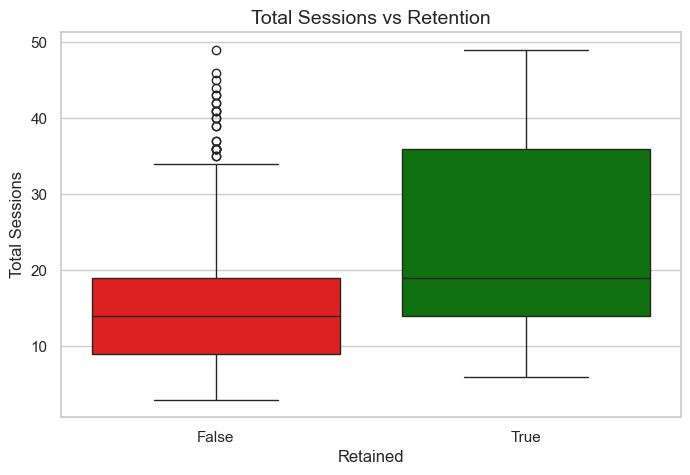

In [25]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='retained',
    y='total_sessions',
    data=analysis_df,
    hue='retained',
    palette={True: "green", False: "red"},
    legend=False
)

plt.title("Total Sessions vs Retention", fontsize=14)
plt.xlabel("Retained", fontsize=12)
plt.ylabel("Total Sessions", fontsize=12)

plt.savefig("../dashboard/sessions_vs_retention.png", bbox_inches="tight")
plt.show()

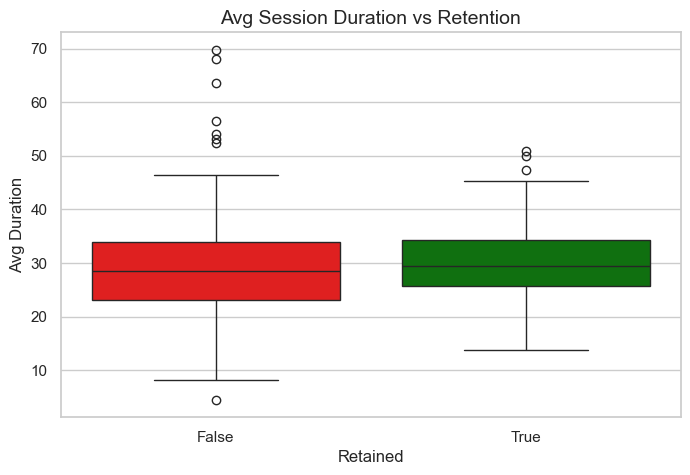

In [26]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x='retained',
    y='avg_duration',
    data=analysis_df,
    hue='retained',
    palette={True: "green", False: "red"},
    legend=False
)

plt.title("Avg Session Duration vs Retention", fontsize=14)
plt.xlabel("Retained", fontsize=12)
plt.ylabel("Avg Duration", fontsize=12)

plt.savefig("../dashboard/duration_vs_retention.png", bbox_inches="tight")
plt.show()

In [17]:
missions_with_retention = missions.merge(retention_flag, on='player_id')

missions_with_retention.head()

,mission_id,player_id,mission_type,mission_duration,success,reward,retained
0,1,1,Interception,15.96,1,231,True
1,2,1,Interception,6.91,1,108,True
2,3,1,Defense,18.52,1,359,True
3,4,1,Survival,18.38,1,355,True
4,5,1,Capture,14.06,1,182,True


In [18]:
missions_with_retention.groupby('mission_type')['success'].mean()

mission_type
Capture         0.849737
Defense         0.843378
Exterminate     0.853484
Interception    0.848054
Survival        0.853557
Name: success, dtype: float64

In [19]:
retention_by_mission = missions_with_retention.groupby('mission_type')['retained'].mean()

retention_by_mission

mission_type
Capture         0.517176
Defense         0.525215
Exterminate     0.515743
Interception    0.511633
Survival        0.525825
Name: retained, dtype: float64

C:\Users\MarsTech\AppData\Local\Temp\ipykernel_13724\2812678302.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


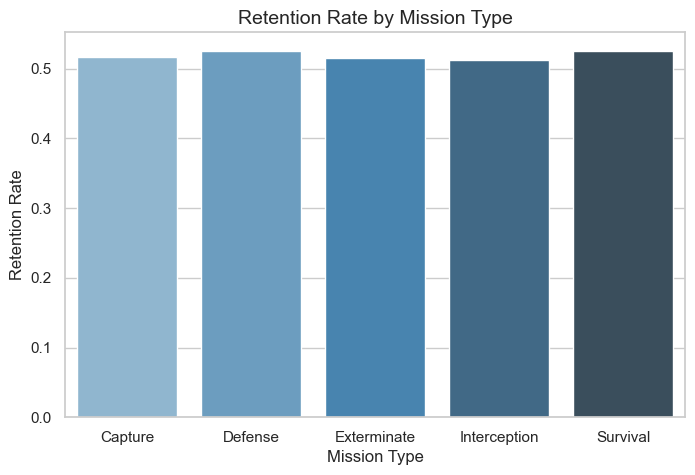

In [28]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=retention_by_mission.index,
    y=retention_by_mission.values,
    palette="Blues_d"
)

plt.title("Retention Rate by Mission Type", fontsize=14)
plt.xlabel("Mission Type", fontsize=12)
plt.ylabel("Retention Rate", fontsize=12)

plt.savefig("../dashboard/mission_retention.png", bbox_inches="tight")
plt.show()